
# Random Forest Classifier

## Step 1 - Import Libraries

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')


## Step 2 - Load Iris Dataset

In [2]:

iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print(X.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


## Step 3 - Understand Dataset

In [3]:

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

print("\nTarget Names")
print(iris.target_names)


Feature Shape : (150, 4)
Target Shape  : (150,)

Target Names
['setosa' 'versicolor' 'virginica']


## Step 4 - Train Test Split

In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print(X_train.shape)
print(X_test.shape)


(120, 4)
(30, 4)


## Step 5 - Create Random Forest Classifier

In [5]:

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## Step 6 - Train Model

In [6]:

model.fit(
    X_train,
    y_train
)

print("Model Trained Successfully")


Model Trained Successfully


## Step 7 - Make Predictions

In [7]:

predictions = model.predict(X_test)

print(predictions)


[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


## Step 8 - Accuracy Score

In [8]:

accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", accuracy)


Accuracy: 1.0


## Step 9 - Confusion Matrix

In [9]:

cm = confusion_matrix(
    y_test,
    predictions
)

print(cm)


[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


## Step 10 - Classification Report

In [10]:

print(
    classification_report(
        y_test,
        predictions
    )
)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## Step 11 - OOB Score (Out-of-Bag Evaluation)

In [11]:

oob_model = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42
)

oob_model.fit(
    X_train,
    y_train
)

print("OOB Score:", oob_model.oob_score_)


OOB Score: 0.9166666666666666


## Step 12 - Feature Importance

In [12]:

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False
)


,Feature,Importance
2,petal length (cm),0.439994
3,petal width (cm),0.421522
0,sepal length (cm),0.108098
1,sepal width (cm),0.030387


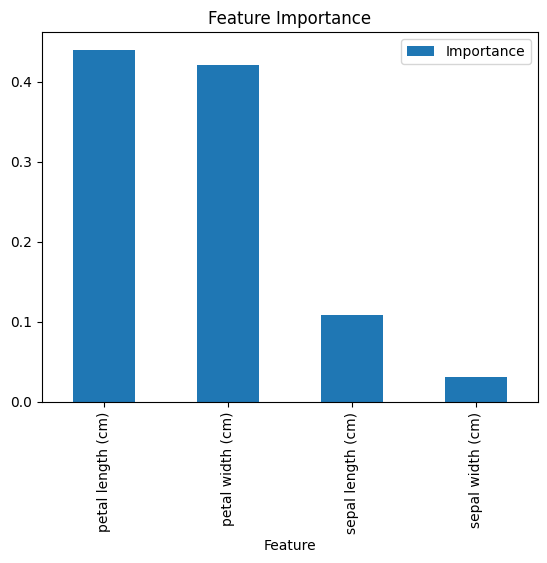

In [13]:

importance.sort_values(
    by='Importance',
    ascending=False
).plot(
    x='Feature',
    y='Importance',
    kind='bar'
)

plt.title("Feature Importance")

plt.show()


## Step 13 - Compare Number of Trees

In [14]:

tree_counts = [1, 5, 10, 50, 100, 200]

results = []

for trees in tree_counts:

    rf = RandomForestClassifier(
        n_estimators=trees,
        random_state=42
    )

    rf.fit(X_train, y_train)

    pred = rf.predict(X_test)

    acc = accuracy_score(
        y_test,
        pred
    )

    results.append(acc)

comparison = pd.DataFrame({
    'Trees': tree_counts,
    'Accuracy': results
})

comparison


,Trees,Accuracy
0,1,1.000000
1,5,0.966667
2,10,1.000000
3,50,1.000000
4,100,1.000000
5,200,1.000000


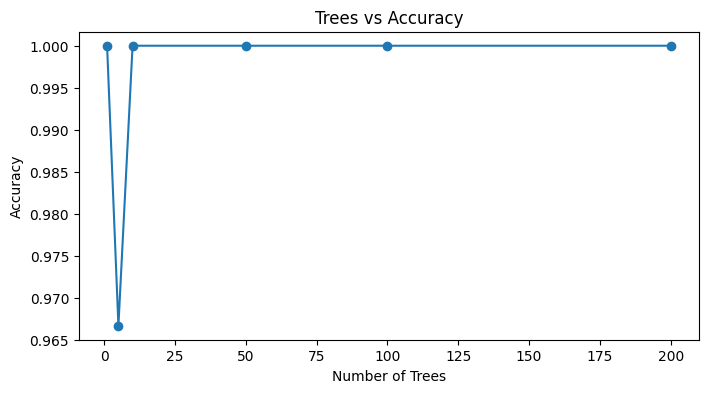

In [15]:

plt.figure(figsize=(8,4))

plt.plot(
    tree_counts,
    results,
    marker='o'
)

plt.xlabel("Number of Trees")
plt.ylabel("Accuracy")

plt.title("Trees vs Accuracy")

plt.show()


## Step 14 - Hyperparameter Tuning Example

In [16]:

tuned_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42
)

tuned_model.fit(
    X_train,
    y_train
)

tuned_pred = tuned_model.predict(
    X_test
)

print(
    "Tuned Accuracy:",
    accuracy_score(
        y_test,
        tuned_pred
    )
)


Tuned Accuracy: 1.0


## Step 15 - Predict New Flower

In [19]:

sample = [[
    5.1,
    3.5,
    1.4,
    0.2
]]

prediction = model.predict(sample)

species = iris.target_names[
    prediction[0]
]

print("Predicted Species:", species)


Predicted Species: setosa
